# In-depth Feature Importance Analysis

This notebook focuses on analyzing the features in the STEG Fraud Detection dataset to identify the most predictive features and suggest candidates for removal.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

%matplotlib inline
sns.set_theme(style="whitegrid")

## 1. Data Loading and Cleaning

In [2]:
# Load aggregated data
df = pd.read_csv('../data/processed/aggregate_train.csv')

# Drop client_id as it's just an identifier
df = df.drop(columns=['client_id'])

# Fill potential NaNs (e.g., from std calculation on single invoices)
df = df.fillna(0)

X = df.drop(columns=['target'])
y = df['target']

## 2. Mutual Information Analysis

Mutual Information (MI) captures any kind of statistical dependency between two variables. It is more robust than correlation for non-linear relationships.

Calculating Mutual Information (this may take a few minutes for 135k rows)...


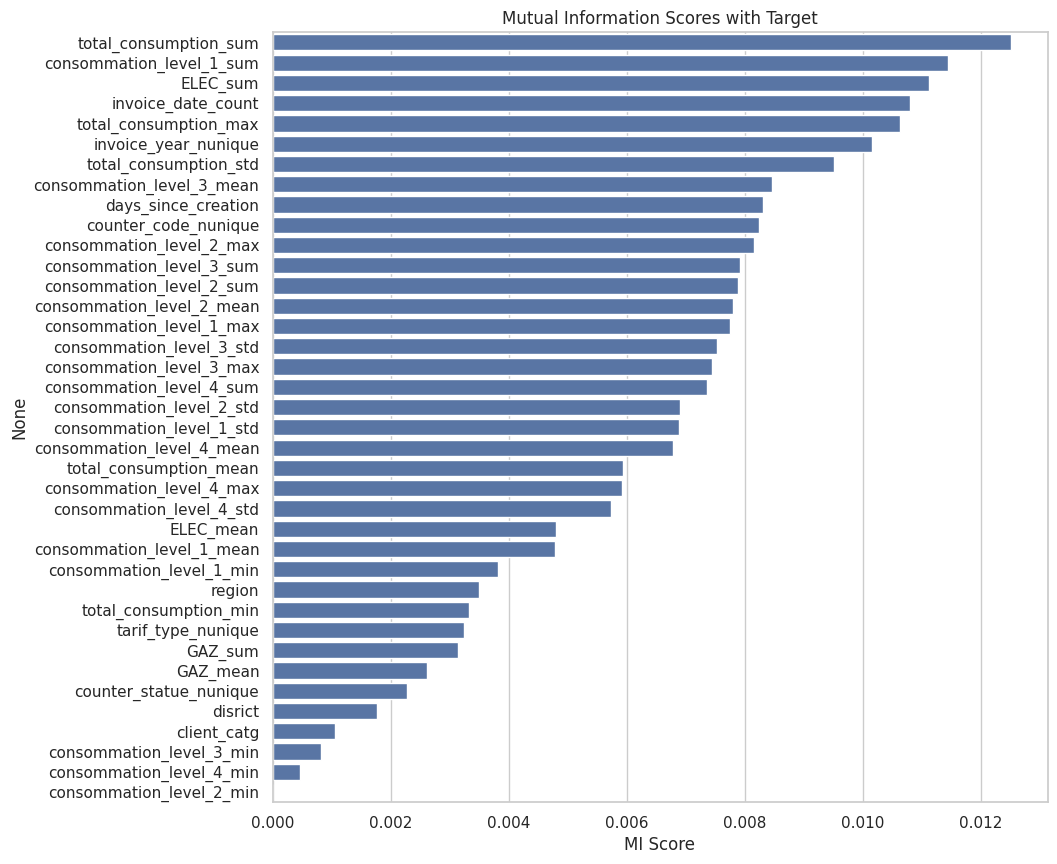

In [3]:
# Identify discrete features for MI (categories and counts)
discrete_features = [
    'disrict', 'client_catg', 'region', 
    'invoice_year_nunique', 'tarif_type_nunique', 
    'counter_statue_nunique', 'counter_code_nunique'
]
discrete_mask = [col in discrete_features for col in X.columns]

print("Calculating Mutual Information (this may take a few minutes for 135k rows)...")
mi_scores = mutual_info_classif(X, y, discrete_features=discrete_mask, random_state=3244)

mi_series = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 10))
sns.barplot(x=mi_series.values, y=mi_series.index)
plt.title("Mutual Information Scores with Target")
plt.xlabel("MI Score")
plt.show()

## 3. Important Feature Distributions by Class

Let's compare the distributions of the top features between the Positive (Fraud) and Negative (No Fraud) classes.

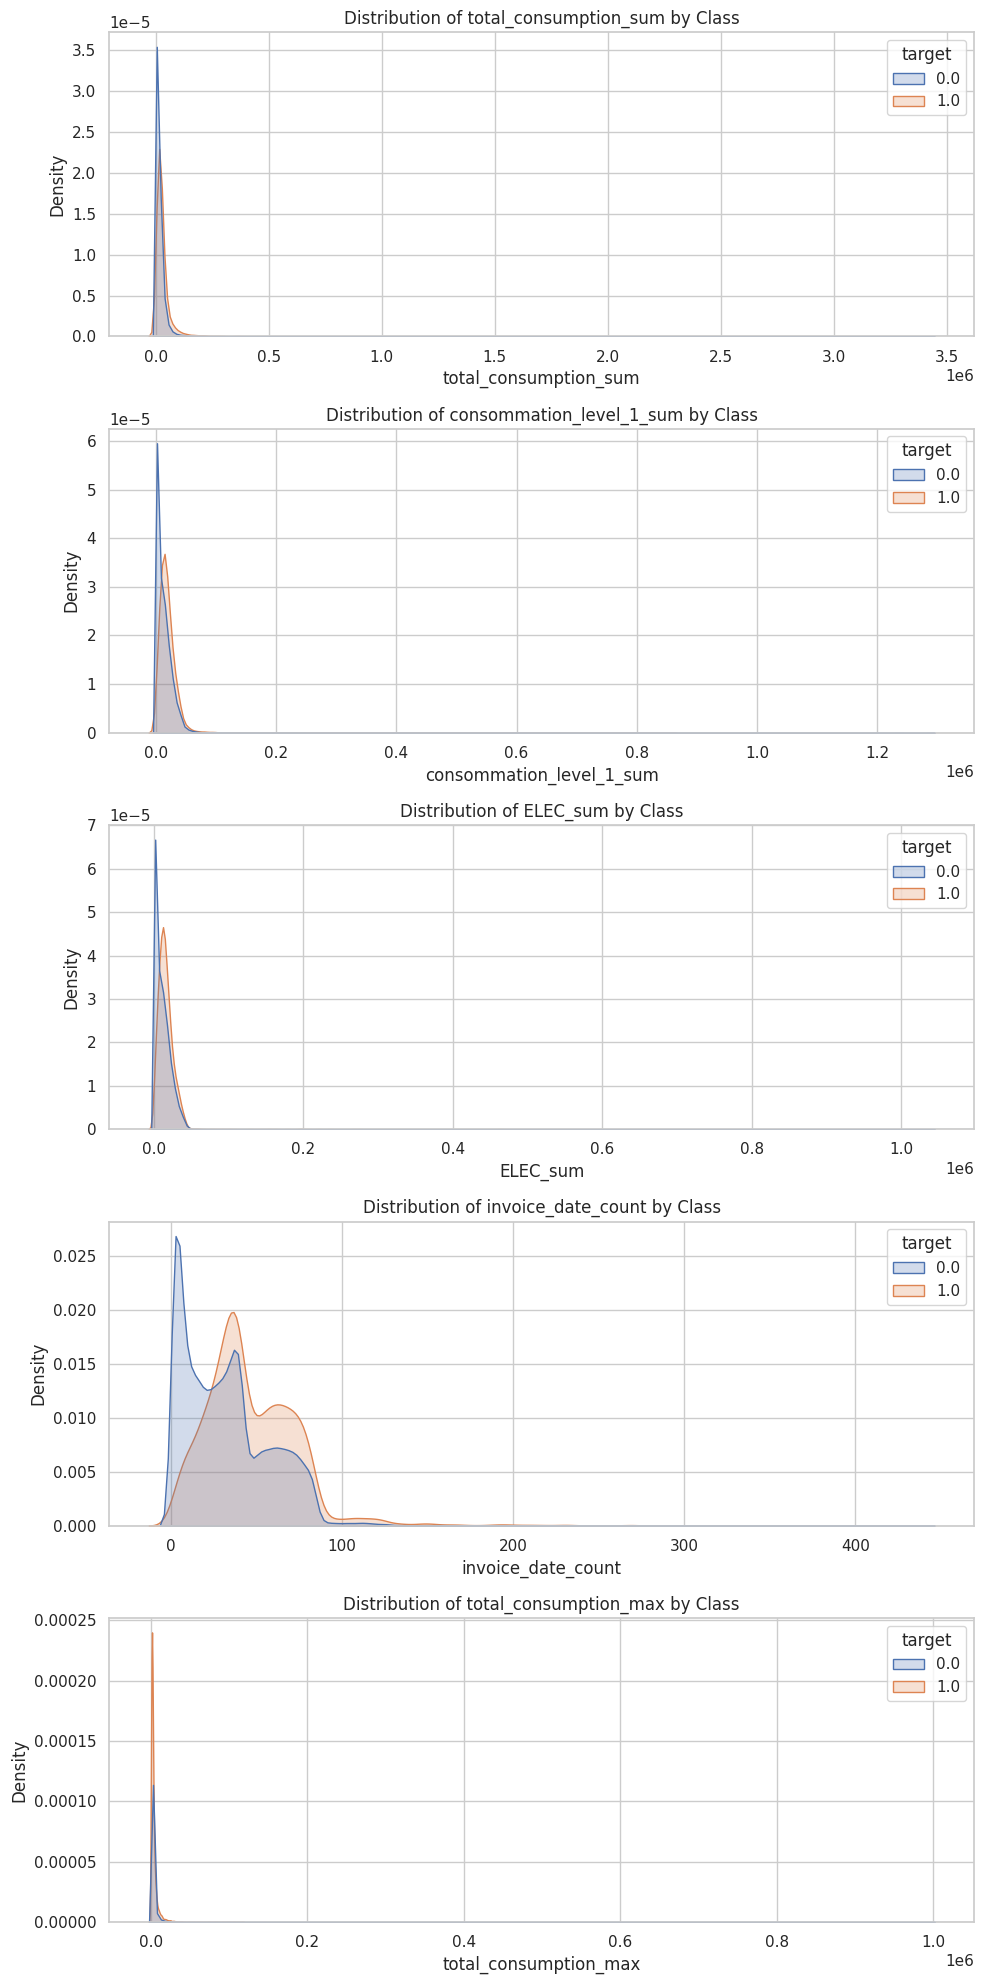

In [4]:
top_5_features = mi_series.head(5).index.tolist()

fig, axes = plt.subplots(len(top_5_features), 1, figsize=(10, 4 * len(top_5_features)))
for i, feature in enumerate(top_5_features):
    sns.kdeplot(data=df, x=feature, hue="target", common_norm=False, ax=axes[i], fill=True)
    axes[i].set_title(f"Distribution of {feature} by Class")
plt.tight_layout()
plt.show()

## 4. Feature Redundancy and Suggestions for Cutting

Features with near-zero MI scores or very high correlation with other features are candidates for removal.

In [5]:
print("Features with lowest MI scores:")
print(mi_series.tail(10))

# Suggesting candidates to drop based on low MI
candidates_to_drop = mi_series[mi_series < 0.001].index.tolist()
print(f"\nCandidates for removal (MI < 0.001): {candidates_to_drop}")

Features with lowest MI scores:
total_consumption_min       3.333616e-03
tarif_type_nunique          3.239262e-03
GAZ_sum                     3.134682e-03
GAZ_mean                    2.613338e-03
counter_statue_nunique      2.278600e-03
disrict                     1.777260e-03
client_catg                 1.058132e-03
consommation_level_3_min    8.241941e-04
consommation_level_4_min    4.583104e-04
consommation_level_2_min    3.596562e-07
dtype: float64

Candidates for removal (MI < 0.001): ['consommation_level_3_min', 'consommation_level_4_min', 'consommation_level_2_min']
